In [13]:
from pathlib import Path
RUN_DIR = "r9.4_fr0_multin_seedU"
grid_fname= Path(f"{RUN_DIR}/d3d_r8.0_pfflat.grd.nc") # Path(f"{RUN_DIR}/d3d_shelf_184016.03506_436_nc3.grd.nc") # 

In [14]:
import numpy as np
run = RUN_DIR
te = np.load(f"{run}/numpy/Te.npy")                # (t, x, y, z)
amp = np.sqrt(((te - te.mean(axis=3, keepdims=True))**2).mean(axis=3)).max(axis=(1, 2))
t = 10.0 * np.arange(len(amp))                     # tau_A
s = slice(len(amp) // 2, None)                     # fit the clean exponential tail
gamma = np.polyfit(t[s], np.log(amp[s]), 1)[0]
print(run, f"gamma = {gamma:.4f} / tau_A")

r9.4_fr0_multin_seedU gamma = 0.0131 / tau_A


/global/cfs/cdirs/m4491/btaczak/bout-runs/r9_scan/runs
r9.4_fr0_multin_seedU: nonlinear run
  missing Da_t.npy -- skipped
  missing Xe_t.npy -- skipped
  missing Xi_t.npy -- skipped
  missing Vr_mean_txy.npy -- skipped
  missing Vexbx_txy.npy -- skipped
  missing Vbtildx_txy.npy -- skipped
  missing ddr_Tetot_txy.npy -- skipped
  missing ddr_Titot_txy.npy -- skipped
  missing ddr_nitot_txy.npy -- skipped
/global/cfs/cdirs/m4491/btaczak/bout-runs/r9_scan/runs
array                 shape                    nt
--------------------------------------------------
--------------------------------------------------
OK: all time-dependent arrays have nt = 1


full_report: old argument order detected -> using coeffs, psin, grid = args[0:3]

TOPOLOGY
TOPOLOGY
  nx=260 ny=64 ixseps1=130 ixseps2=260
  jyseps1_1=7 jyseps2_1=32 jyseps1_2=32 jyseps2_2=59
  poloidal cells: inner leg 8, outer leg 4
  -> FEWER THAN 12 CELLS IN A LEG.  C2 parallel derivatives plus a sheath BC on that few points is under-resolved.
  PF_limit cut: ix >= 128 (= ceil(0.98*130)), psi_n = 0.9996; 2 PF cell(s) between the cut and the separatrix.
  PF_filter() overwrites Ni,Ti,Te,U,P,phi,Jpar,Apar but NOT ddt():
  the PF region keeps evolving in CVODE, it is only zeroed in the dumps.
  PF_sink damping that fades out before the separatrix: PFs_width = 0.01, PFs_length = 0.470
  PF_sink damping that fades out before the separatrix: PFs_width = 0.02, PFs_length = 0.440
  Bp < 0.04 T in 217 cells (j = [7, 8, 59, 60]...)
  hthe < 0.04 m in 0 cells
  local q: core rows median 4.94, leg rows max 22.06 -> chi_neo ~ q^2 is x20 larger in the legs
  zShift step across PF connection (j=7

ValueError: 
$\log_{10} q_{loc}$ (floored $B_p$)
^
ParseException: Expected end of text, found '$'  (at char 0), (line:1, col:1)

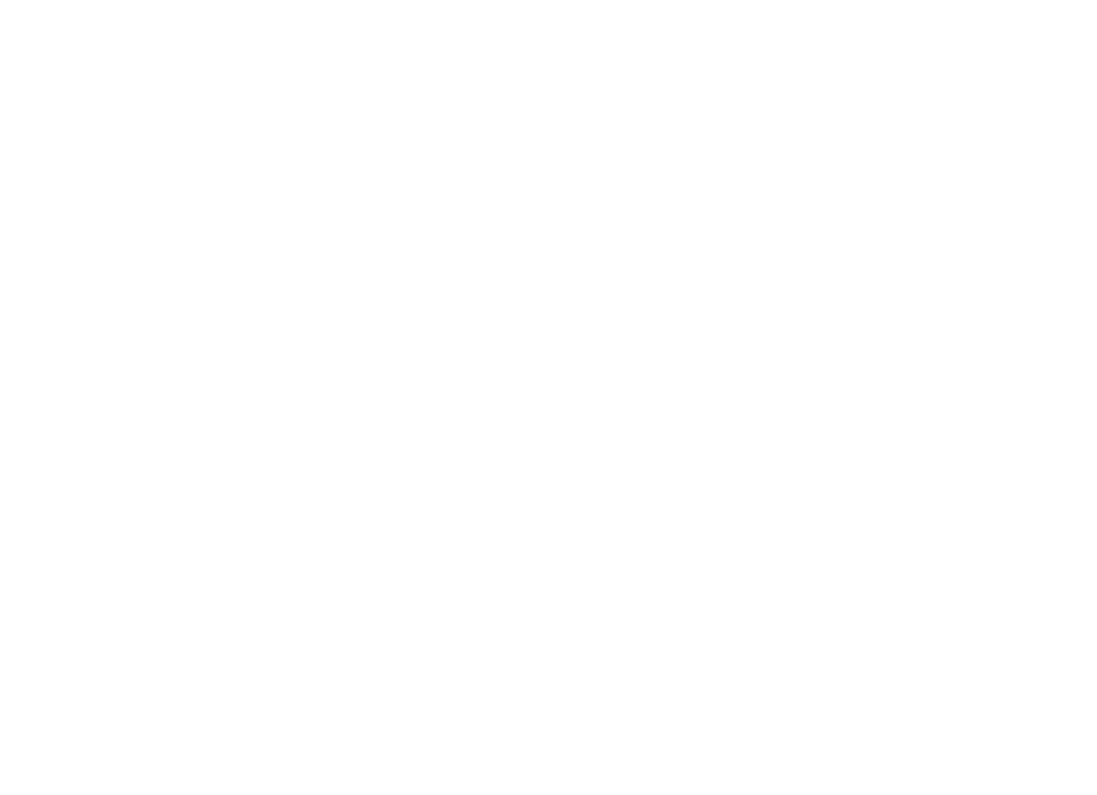

In [16]:
import os
import sys
sys.path.append("/global/cfs/projectdirs/m4491/btaczak/SOLPS-BOUT-coupling/scripts")
import re
import yaml
import numpy as np
import netCDF4 as nc
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from boutdata.data import BoutData
from boututils.datafile import DataFile
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FormatStrFormatter
from ipywidgets import interact, IntSlider, fixed
from sibil_io_functions import load_config, sibil_config_summary, confirm, parse_tdata2, parse_block_sizes, write_updated_namelist, _format_value, extract_tdata_first_index, interpolate_dataset, get_midplane_distances_from_psin, vec_summary, set_tdata2_block, get_bout_midplane_distances
from converged_profile_functions import unbiased_convergence, end_biased_convergence
import sibil_debug_diagnostics as dbg

!echo $PWD
data_dir = f"{RUN_DIR}/numpy"
grid_fname = str(grid_fname)
transport_coeffs = ["Da_t", "Xe_t", "Xi_t", "Vr_mean_txy", "Vexbx_txy", "Vbtildx_txy",
                    "ddr_Tetot_txy", "ddr_Titot_txy", "ddr_nitot_txy"]
jomp = 44
N, l = 0, 7

grid = DataFile(grid_fname)
psi_bndry = grid["psi_bdry"] if "psi_bdry" in grid.keys() else grid["psi_bndry"]
psin = ((grid["psixy"] - grid["psi_axis"]) / (psi_bndry - grid["psi_axis"]))[:, jomp]

psin_mid, sepx_dists_bout = get_bout_midplane_distances(grid_fname)

linear = dbg.is_linear_run(RUN_DIR, data_dir)
print(f"{RUN_DIR}: {'LINEAR run (nonlinear = false) -- no D/chi, linear diagnostics only' if linear else 'nonlinear run'}")

convergent_transport_coeffs = {}
interplted_transport_coeffs = {}
for var_name in transport_coeffs:
    path = f"{data_dir}/{var_name}.npy"
    if not os.path.exists(path):
        if not linear:
            print(f"  missing {var_name}.npy -- skipped")
        continue
    if "ddr" in var_name:
        print(var_name)
        convergent_transport_coeffs[var_name] = np.load(path)
        continue
    convergent_transport_coeffs[var_name] = unbiased_convergence(np.load(path), None, None)

import sibil_debug_diagnostics as dbg
!echo $PWD
display(dbg.make_debug_widget(convergent_transport_coeffs, psin_mid,
                              jomp=jomp, grid=grid, data_dir=data_dir))
dbg.full_report(convergent_transport_coeffs, psin_mid, grid_fname, jomp=jomp,
                savedir=f"./crash_diagnostics/{RUN_DIR}", run=RUN_DIR)
!echo $PWD

import matplotlib.pyplot as plt
import boututils.efit_analyzer as ea
from boututils.read_geqdsk import read_geqdsk

ea.show = lambda *args, **kwargs: None

g = read_geqdsk("/global/cfs/projectdirs/m4491/btaczak/SIBIL-runs/DIIID_LSN_noC_corrected_heat_flux_test/g184016.03200")
ea.View2D(g, option=0)
plt.show()